<a href="https://colab.research.google.com/github/moysessevan/termodinamica-python/blob/main/cod_1_3_gas_ideal_isotermas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Primeiras linhas da tabela:
   Volume_Especifico (m3/kg)  P_300K (kPa)  P_400K (kPa)  P_500K (kPa)
0                   0.100000    861.174000   1148.232000   1435.290000
1                   0.118367    727.543552    970.058069   1212.572586
2                   0.136735    629.813821    839.751761   1049.689701
3                   0.155102    555.230605    740.307474    925.384342
4                   0.173469    496.441482    661.921976    827.402471

Resumo estatistico das propriedades:
       Volume_Especifico (m3/kg)  P_300K (kPa)  P_400K (kPa)  P_500K (kPa)
count                  50.000000     50.000000     50.000000     50.000000
mean                    0.550000    225.651681    300.868908    376.086135
std                     0.267748    174.089815    232.119753    290.149692
min                     0.100000     86.117400    114.823200    143.529000
25%                     0.325000    111.131070    148.174760    185.218450
50%                     0.550000    156.620758    208.8276

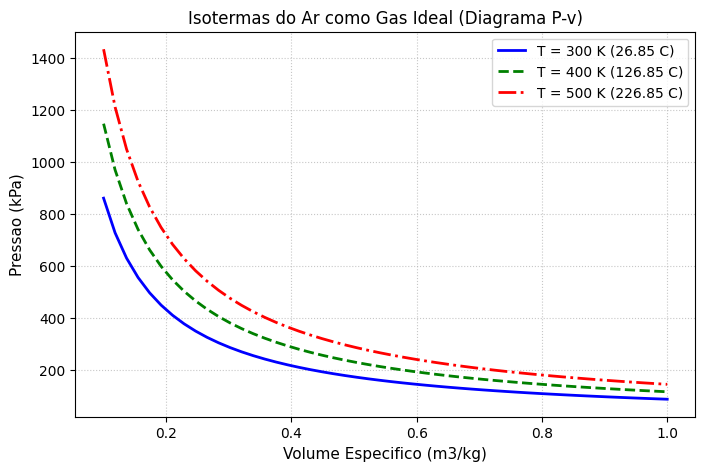

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Constante particular do Ar Seco (Ru / M = 8.31446 / 0.02897)
R_ar = 287.058  # J/(kg.K)

# Criando um vetor (array) com 50 valores de volume especifico de 0.1 a 1.0 m3/kg
v = np.linspace(0.1, 1.0, 50)

# Calculando a pressao (em Pa) para tres isotermas diferentes (vetorizacao)
P_300K = (R_ar * 300.0) / v
P_400K = (R_ar * 400.0) / v
P_500K = (R_ar * 500.0) / v

# --- USO DO PANDAS: ORGANIZACAO, ANALISE E EXPORTACAO ---
# 1. Organizando os resultados em uma tabela estruturada (DataFrame)
tabela_isotermas = pd.DataFrame({
    'Volume_Especifico (m3/kg)': v,
    'P_300K (kPa)': P_300K / 1000.0,
    'P_400K (kPa)': P_400K / 1000.0,
    'P_500K (kPa)': P_500K / 1000.0
})

# 2. Exibindo as 5 primeiras linhas e o resumo estatistico da tabela
print("Primeiras linhas da tabela:")
print(tabela_isotermas.head())

print("\nResumo estatistico das propriedades:")
print(tabela_isotermas.describe())

# 3. Filtrando pontos de operacao (ex: pressao acima de 500 kPa a 300 K)
alta_pressao = tabela_isotermas[tabela_isotermas['P_300K (kPa)'] > 500]
print("\nCondicoes com pressao superior a 500 kPa (T = 300 K):")
print(alta_pressao)

# 4. Exportando a tabela completa para Excel (.xlsx) no Colab
tabela_isotermas.to_excel('isotermas_ar_ideal.xlsx', index=False)

# --- VISUALIZACAO GRAFICA (MATPLOTLIB) ---
plt.figure(figsize=(8, 5))
plt.plot(tabela_isotermas['Volume_Especifico (m3/kg)'], tabela_isotermas['P_300K (kPa)'],
         label='T = 300 K (26.85 C)', color='blue', linewidth=2)
plt.plot(tabela_isotermas['Volume_Especifico (m3/kg)'], tabela_isotermas['P_400K (kPa)'],
         label='T = 400 K (126.85 C)', color='green', linewidth=2, linestyle='--')
plt.plot(tabela_isotermas['Volume_Especifico (m3/kg)'], tabela_isotermas['P_500K (kPa)'],
         label='T = 500 K (226.85 C)', color='red', linewidth=2, linestyle='-.')

plt.title('Isotermas do Ar como Gas Ideal (Diagrama P-v)', fontsize=12)
plt.xlabel('Volume Especifico (m3/kg)', fontsize=11)
plt.ylabel('Pressao (kPa)', fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()